# When Confidence Intervals Lie: the Epistemology of CIs and the Bootstrap

**What you'll learn**

- What a 95% CI *actually* claims — a promise about a **procedure over repetitions**, not about your one interval — and why that distinction has practical teeth.
- The premise stack hidden behind every printed interval (sampling model, approximation, no selection, no bias), and a demonstration of what happens to coverage when each premise fails.
- The three great lies: **dependence** (the imagined repetition is wrong), **selection** (you looked before you promised), and **bias** (the CI is silent about everything except sampling noise — including in the big-data regime where intervals become tiny and wrong).
- The bootstrap as an **epistemological thought experiment** — "resample from a world exactly like my sample" — and a checklist for when that thought experiment is sound.
- When a CI answers a question nobody asked: census data, process drift, and choosing the repetition that matches your actual question.

**Why it matters in interviews**

- "What does 95% confidence mean?" is a filter question at every level; senior candidates are expected to go beyond the textbook line to *when the guarantee is void*.
- Winner's curse, selective reporting, and "we have all the data, why a CI?" are recurring senior-round probes.
- Distinguishing *precisely wrong* from *honestly uncertain* is the difference between a metric reader and a decision scientist.

Deep-dive companions: [01_sampling_clt_bootstrap](01_sampling_clt_bootstrap.ipynb) (bootstrap mechanics and failure modes),
[04_statistical_traps](04_statistical_traps.ipynb) (multiple testing, winner's curse),
[../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb) (selection in time),
[../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb) (clustered data),
[../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb) (credible intervals).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## 1. What a 95% CI actually claims

The frequentist contract, stated carefully:

> *If* the assumed sampling model is true, and *if* you ran this **procedure** on endless fresh
> samples, then **95% of the intervals it produces** would contain the fixed, unknown parameter.

The 95% is a property of the **assembly line**, not of the item in your hands. After the data are
observed, your specific interval either contains the parameter or it doesn't — there is no 95%
probability left *for the frequentist* (the Bayesian can keep a probability, but only by paying
with a prior; see the Bayesian module).

Let's watch the assembly line work when all premises hold: iid samples from a skewed
revenue-like population, t-intervals for the mean, n large enough for the CLT to have done its job.

In [2]:
truth_shape, truth_scale = 4.0, 2.5           # Gamma population
TRUE_MEAN = truth_shape * truth_scale          # = 10, known because we play god
n, reps = 200, 5000

samples = rng.gamma(truth_shape, truth_scale, size=(reps, n))
means = samples.mean(axis=1)
ses = samples.std(axis=1, ddof=1) / np.sqrt(n)
tcrit = stats.t.ppf(0.975, df=n - 1)
lo, hi = means - tcrit * ses, means + tcrit * ses
covered = (lo <= TRUE_MEAN) & (TRUE_MEAN <= hi)
print(f"Coverage of the t-interval procedure over {reps} repetitions: {covered.mean():.3f}")

Coverage of the t-interval procedure over 5000 repetitions: 0.951


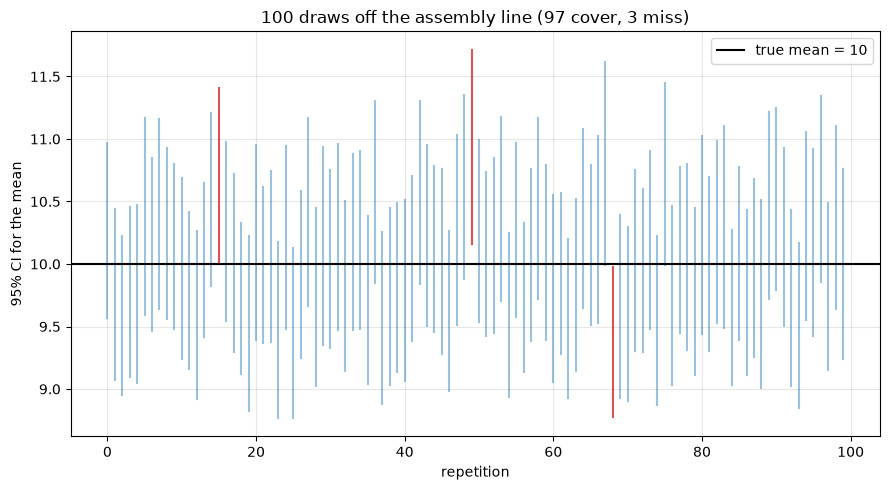

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
show = 100
for i in range(show):
    color = "tab:blue" if covered[i] else "tab:red"
    ax.plot([i, i], [lo[i], hi[i]], color=color, lw=1.5,
            alpha=0.8 if not covered[i] else 0.45)
ax.axhline(TRUE_MEAN, color="k", lw=1.5, label=f"true mean = {TRUE_MEAN:.0f}")
ax.set_title(f"100 draws off the assembly line ({covered[:show].sum()} cover, "
             f"{show - covered[:show].sum()} miss)")
ax.set_xlabel("repetition"); ax.set_ylabel("95% CI for the mean"); ax.legend()
plt.tight_layout(); plt.show()

When the premises hold, the machine delivers: ~95% of intervals cover. **Every claim in the rest
of this notebook is about what happens when a premise fails** — the software keeps printing
intervals either way.

### Fisher's objection: relevant subsets

Even when marginal coverage is exactly right, it can be **misleading for your particular
dataset**. Classic toy example: two observations from Uniform(θ − 0.5, θ + 0.5), and the
"confidence interval" `[min(x), max(x)]`. Marginally this covers θ exactly 50% of the time —
a valid 50% CI. But you can *see from the data* when it is certain and when it is nearly hopeless:
if the two points are more than 0.5 apart, the interval **must** contain θ.

Marginal coverage of [min, max]: 0.504  (a perfectly valid 50% CI)


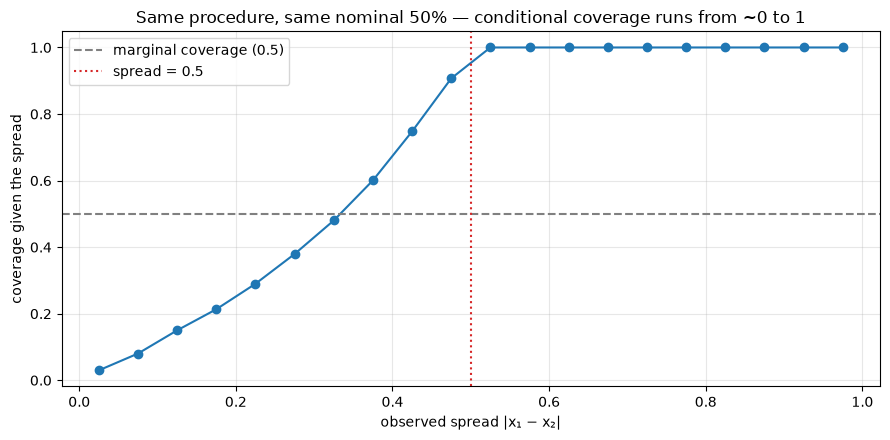

In [4]:
theta = 7.3
reps2 = 100_000
x2 = rng.uniform(theta - 0.5, theta + 0.5, size=(reps2, 2))
lo2, hi2 = x2.min(axis=1), x2.max(axis=1)
cov2 = (lo2 <= theta) & (theta <= hi2)
spread = hi2 - lo2
print(f"Marginal coverage of [min, max]: {cov2.mean():.3f}  (a perfectly valid 50% CI)")

bins = np.linspace(0, 1, 21)
mids = 0.5 * (bins[:-1] + bins[1:])
cond = [cov2[(spread >= a) & (spread < b)].mean() for a, b in zip(bins[:-1], bins[1:])]

fig, ax = plt.subplots()
ax.plot(mids, cond, "o-")
ax.axhline(0.5, color="gray", ls="--", label="marginal coverage (0.5)")
ax.axvline(0.5, color="tab:red", ls=":", label="spread = 0.5")
ax.set_xlabel("observed spread |x₁ − x₂|")
ax.set_ylabel("coverage given the spread")
ax.set_title("Same procedure, same nominal 50% — conditional coverage runs from ~0 to 1")
ax.legend(); plt.tight_layout(); plt.show()

The nominal level is an **average over datasets you didn't get**. When recognizable features of
your data (here: the spread) predict whether the interval covers, the marginal number can be
almost irrelevant to your case. Real-world analogue: an interval procedure that is honest on
average across metrics, but systematically overcovers stable metrics and undercovers volatile
ones — the dashboard-wide "95%" tells you little about *this* metric.

## 2. The premise stack

Every printed CI is the conclusion of a theorem. The premises are not checked by the software:

| Premise | What it says | What breaks it |
|---|---|---|
| **Sampling model** | The data are (say) iid draws from the population you care about | Dependence (users, time), drift, convenience samples |
| **Approximation** | The estimator's sampling distribution is ≈ the assumed one (CLT, asymptotics) | Small n, heavy tails, extreme quantiles, boundary parameters |
| **No selection** | *This* estimate/interval was chosen before looking at the data | Reporting only significant results, picking the best variant, peeking |
| **No bias** | Sampling noise is the only error | Measurement error, non-response, survivorship, leaky pipelines |

The next three sections break one premise at a time and *measure* what it does to coverage.

## 3. Lie #1 — dependence: the imagined repetition is the wrong one

An iid CI imagines a world where every observation is an independent draw. If your daily metric
is autocorrelated, the real world produces far fewer *effective* observations than the imagined
one — the SE is understated and the interval is too tight. (The clustered version of this lie —
sessions inside users — is dissected in
[../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb).)

In [5]:
rho, n3, reps3 = 0.6, 200, 4000
eps = rng.normal(size=(reps3, n3))
ar = np.empty_like(eps)
ar[:, 0] = eps[:, 0] / np.sqrt(1 - rho**2)     # stationary start
for t in range(1, n3):
    ar[:, t] = rho * ar[:, t - 1] + eps[:, t]  # true mean is 0

m3 = ar.mean(axis=1)
se3 = ar.std(axis=1, ddof=1) / np.sqrt(n3)     # iid formula — wrong here
cover_naive = np.abs(m3) <= tcrit * se3
vif = (1 + rho) / (1 - rho)
print(f"AR(1) with rho={rho}: naive iid 95% CI coverage = {cover_naive.mean():.3f}")
print(f"Variance inflation factor ≈ (1+rho)/(1-rho) = {vif:.0f} "
      f"→ the honest SE is ~{np.sqrt(vif):.1f}x the naive one")

AR(1) with rho=0.6: naive iid 95% CI coverage = 0.662
Variance inflation factor ≈ (1+rho)/(1-rho) = 4 → the honest SE is ~2.0x the naive one


Nominally 95%, actually ~66%. Nothing about the *formula* is wrong — it answers a question about
a world that didn't generate your data. Fixes (Newey–West SEs, block/cluster bootstrap,
aggregating to the independent unit) all amount to the same move: **make the imagined repetition
match the real dependence structure.**

## 4. Lie #2 — selection: you looked before you promised

Coverage is a *pre-data* promise. Conditioning on what the data showed — reporting only
significant results, showcasing the best variant, stopping when the result looks good — changes
the relevant repetition to "datasets where I would have reported this", and on that repetition
the nominal level is generally false.

### Winner's curse: CIs of significant results

Run underpowered experiments with a real effect. Look at coverage **among the ones that reached
significance** — the only ones most organizations ever hear about.

In [6]:
delta, n4, reps4 = 0.3, 50, 40_000            # true lift 0.3σ, ~30% power
a = rng.normal(0.0, 1.0, size=(reps4, n4))
b = rng.normal(delta, 1.0, size=(reps4, n4))
diff = b.mean(1) - a.mean(1)
se4 = np.sqrt(a.var(1, ddof=1) / n4 + b.var(1, ddof=1) / n4)
z = diff / se4
sig = np.abs(z) > 1.96
cover4 = np.abs(diff - delta) <= 1.96 * se4

print(f"Power (share significant):                     {sig.mean():.2f}")
print(f"Coverage, all experiments:                     {cover4.mean():.3f}")
print(f"Coverage, significant experiments only:        {cover4[sig].mean():.3f}")
print(f"Mean estimated lift among significant:         {diff[sig].mean():.2f} "
      f"(true: {delta}) → exaggeration x{diff[sig].mean()/delta:.1f}")
print(f"Significant with the WRONG sign:               {(sig & (diff < 0)).mean()/sig.mean():.1%} of reported results")

Power (share significant):                     0.32
Coverage, all experiments:                     0.948
Coverage, significant experiments only:        0.920
Mean estimated lift among significant:         0.52 (true: 0.3) → exaggeration x1.7
Significant with the WRONG sign:               0.1% of reported results


The procedure is fine *marginally* — but the published subset lies: coverage slips below
nominal and, more damningly, the point estimates are inflated ~1.7x (Type M error; see
[04_statistical_traps](04_statistical_traps.ipynb)). The CI you read in a "significant wins" deck
is not a 95% CI on the repetition that produced it.

### Picking the best of K

Same mechanism, purer form: run 10 variants with **identical** true means and report a standard
CI for the winner.

In [7]:
K, n5, reps5 = 10, 100, 20_000
x5 = rng.normal(0.0, 1.0, size=(reps5, K, n5))     # all true means = 0
m5 = x5.mean(axis=2)
s5 = x5.std(axis=2, ddof=1) / np.sqrt(n5)
best = m5.argmax(axis=1)
idx = np.arange(reps5)
best_mean, best_se = m5[idx, best], s5[idx, best]
cover5 = np.abs(best_mean - 0.0) <= 1.96 * best_se
print(f"Coverage of the naive 95% CI for the best-of-{K} arm's true mean: {cover5.mean():.3f}")
print(f"Average estimated mean of the 'winner' (truth is 0): {best_mean.mean():.3f}")

Coverage of the naive 95% CI for the best-of-10 arm's true mean: 0.761
Average estimated mean of the 'winner' (truth is 0): 0.154


Selection turned a 95% interval into a ~76% one, and manufactured a positive "effect" out of
noise. Remedies: pre-registration (restores the pre-data promise), holdout validation of the
winner, selective-inference corrections, or shrinkage/hierarchical estimates
([../06_bayesian_methods/03_hierarchical_models.ipynb](../06_bayesian_methods/03_hierarchical_models.ipynb)).
Optional stopping is the same lie played out in time —
[../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb).

## 5. Lie #3 — bias: the CI is silent about everything except sampling noise

A CI quantifies **one** source of error: the noise of random sampling. Measurement error,
non-response, survivorship, and selection into the sample are all invisible to it. This becomes
vicious at scale — the **big-data paradox** (Meng, 2018): as n grows, the interval shrinks
toward a point, and if there is *any* correlation between being-in-the-sample and the outcome,
it shrinks toward the **wrong** point.

Population of 1M users; we want the mean satisfaction score. Compare a small random sample
against a huge convenience sample (opt-in feedback, where happier users respond slightly more).

In [8]:
N_POP = 1_000_000
y_pop = rng.normal(50.0, 10.0, size=N_POP)
TRUE_POP_MEAN = y_pop.mean()

def mcar_ci(rng, n):
    s = rng.choice(y_pop, size=n, replace=False)
    m, se = s.mean(), s.std(ddof=1) / np.sqrt(n)
    return m, m - 1.96 * se, m + 1.96 * se

def optin_ci(rng):
    # response probability mildly increasing in y: ~35%..65% across the score range
    p = 1 / (1 + np.exp(-(y_pop - 50.0) / 16.0)) * 0.6 + 0.2
    take = rng.random(N_POP) < p
    s = y_pop[take]
    m, se = s.mean(), s.std(ddof=1) / np.sqrt(len(s))
    return m, m - 1.96 * se, m + 1.96 * se, len(s)

R = 60
mcar = np.array([mcar_ci(rng, 400)[:3] for _ in range(R)])
opt = np.array([optin_ci(rng)[:3] for _ in range(R)])
n_optin = optin_ci(rng)[3]
mcar_cover = ((mcar[:, 1] <= TRUE_POP_MEAN) & (TRUE_POP_MEAN <= mcar[:, 2])).mean()
opt_cover = ((opt[:, 1] <= TRUE_POP_MEAN) & (TRUE_POP_MEAN <= opt[:, 2])).mean()

print(f"True population mean: {TRUE_POP_MEAN:.2f}")
print(f"Random sample, n=400:        mean CI width {np.mean(mcar[:,2]-mcar[:,1]):.2f}, coverage {mcar_cover:.2f}")
print(f"Opt-in sample, n≈{n_optin:,}: mean CI width {np.mean(opt[:,2]-opt[:,1]):.3f}, coverage {opt_cover:.2f}, "
      f"typical estimate {opt[:,0].mean():.2f}")

True population mean: 49.98
Random sample, n=400:        mean CI width 1.94, coverage 0.98
Opt-in sample, n≈499,469: mean CI width 0.055, coverage 0.00, typical estimate 51.70


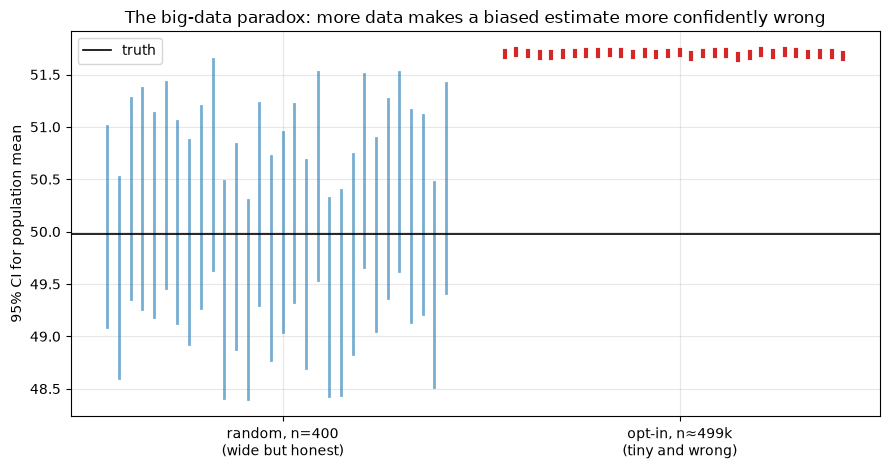

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for i in range(30):
    ax.plot([i, i], [mcar[i, 1], mcar[i, 2]], color="tab:blue", lw=2, alpha=0.6)
    ax.plot([i + 34, i + 34], [opt[i, 1], opt[i, 2]], color="tab:red", lw=3)
ax.axhline(TRUE_POP_MEAN, color="k", lw=1.2, label="truth")
ax.set_xticks([15, 49]); ax.set_xticklabels(["random, n=400\n(wide but honest)",
                                             f"opt-in, n≈{n_optin//1000}k\n(tiny and wrong)"])
ax.set_ylabel("95% CI for population mean")
ax.set_title("The big-data paradox: more data makes a biased estimate more confidently wrong")
ax.legend(); plt.tight_layout(); plt.show()

Half a million observations, immaculate arithmetic, 0% coverage. **Total error = bias + noise;
the CI sees only noise.** When n is huge, the first question is never "what's the CI?" — it's
"what's the correlation between being in this dataset and the thing I'm measuring?"

## 6. The bootstrap's epistemology: the plug-in thought experiment

The bootstrap answers a precisely-posed question: *"if the world were exactly my sample
(the empirical distribution F̂), what would the sampling variability of my statistic look like?"*
Its soundness therefore rests on two premises:

1. **F̂ is a good stand-in for F** *for the functional you care about* — true for smooth
   functionals (means, ratios, interior quantiles, regression coefficients) at moderate n.
2. **The resampling scheme mirrors the real repetition** — iid resampling for iid data;
   blocks for time series; clusters for grouped data.

Both premises are epistemological claims about how well your sample represents the world.
Two compact failure demos (the full tour is in
[01_sampling_clt_bootstrap](01_sampling_clt_bootstrap.ipynb)):

In [10]:
# Failure A — a non-smooth boundary functional: the maximum.
# The plug-in world's max can never exceed the observed max, so the interval's upper end
# can never reach past the data toward the true θ — coverage is not just low, it is zero.
theta6, n6, reps6, B = 1.0, 50, 1000, 800
misses = 0
for _ in range(reps6):
    x6 = rng.uniform(0, theta6, n6)
    bmax = np.array([x6[rng.integers(0, n6, n6)].max() for _ in range(B)])
    lo6, hi6 = np.percentile(bmax, [2.5, 97.5])
    misses += not (lo6 <= theta6 <= hi6)
print(f"Bootstrap percentile 95% CI for the max of U(0,θ): coverage {1 - misses/reps6:.3f}")

Bootstrap percentile 95% CI for the max of U(0,θ): coverage 0.000


In [11]:
# Failure B — tiny n: the bootstrap cannot create information the sample doesn't hold.
n7, reps7, B7 = 8, 2000, 2000
miss7 = 0
true_mean7 = np.exp(0.5)          # mean of LogNormal(0,1)
for _ in range(reps7):
    x7 = rng.lognormal(0.0, 1.0, n7)
    bmeans = np.array([x7[rng.integers(0, n7, n7)].mean() for _ in range(B7)])
    lo7, hi7 = np.percentile(bmeans, [2.5, 97.5])
    miss7 += not (lo7 <= true_mean7 <= hi7)
print(f"Bootstrap percentile 95% CI for a lognormal mean at n=8: coverage {1 - miss7/reps7:.3f}")

Bootstrap percentile 95% CI for a lognormal mean at n=8: coverage 0.762


**When the bootstrap is sound vs not — the checklist:**

| Sound | Unsound (or needs surgery) |
|---|---|
| Smooth functionals: means, differences, ratios, coefficients, interior quantiles | Extremes (max/min, p99.9 at small n), parameters on a boundary |
| Moderate-to-large n from the population of interest | Tiny n (the empirical distribution is a poor world model — and it *inherits every bias* of the sample) |
| Resampling that mirrors the real repetition (iid ↔ iid; cluster bootstrap for users; block bootstrap for time series) | iid resampling of dependent data (silently understates variance) |
| Estimators whose behavior varies smoothly with the data | Non-smooth procedures (nearest-neighbor matching — see [../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb](../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb)); post-selection statistics (bootstrap does NOT fix the selection lies of §4) |

## 7. When does a CI answer your actual question? Census data and drift

"We have data on **all** our users — why report a CI at all?" A senior answer distinguishes two
questions:

- **Descriptive**: "what was the mean revenue of March users?" You have the population; the
  number has no sampling error. A CI is theater.
- **Process**: "what does March tell me about April, or about the system generating months?"
  Now there *is* uncertainty — but the relevant repetition is **months**, not users-within-March.

The common failure mode: computing the within-month (user-level) CI and treating it as
uncertainty about the process. With any month-to-month drift, that interval is wildly
overconfident, because user-level noise is not the binding uncertainty.

In [12]:
reps8, months, n_users, sd_user, sd_month = 3000, 24, 2000, 15.0, 2.0
se_user = sd_user / np.sqrt(n_users)
# monthly true means drift around 100; we observe monthly sample means
month_eff = rng.normal(0.0, sd_month, size=(reps8, months + 1))
obs = 100 + month_eff + rng.normal(0.0, se_user, size=(reps8, months + 1))
last, nxt = obs[:, months - 1], 100 + month_eff[:, months]   # predict next month's true mean

within = np.abs(last - nxt) <= 1.96 * se_user                # user-level CI from last month
s_m = obs[:, :months].std(axis=1, ddof=1)                    # month-level history, n=24
tpred = stats.t.ppf(0.975, months - 1) * s_m * np.sqrt(1 + 1 / months)
monthly = np.abs(obs[:, :months].mean(axis=1) - nxt) <= tpred

print(f"User-level 95% CI from the latest month, used to 'predict' next month's mean:")
print(f"  width ±{1.96*se_user:.2f} → coverage {within.mean():.3f}")
print(f"Month-level 95% prediction interval from {months} monthly means:")
print(f"  width ±{tpred.mean():.2f} → coverage {monthly.mean():.3f}")

User-level 95% CI from the latest month, used to 'predict' next month's mean:
  width ±0.66 → coverage 0.187
Month-level 95% prediction interval from 24 monthly means:
  width ±4.25 → coverage 0.960


The tight interval answers a question nobody asked (sampling noise of users within a month you
already fully observed); the honest interval treats **months** as the unit of repetition and is
several times wider. Choosing the repetition *is* the analysis.

## 8. Pitfalls

### Pitfall 1: "the CIs overlap, so the difference isn't significant"

In [13]:
# Two groups, constructed so individual 95% CIs overlap while the difference is significant.
se_g = 0.15
m_a, m_b = 0.0, 0.50
ci_a = (m_a - 1.96 * se_g, m_a + 1.96 * se_g)
ci_b = (m_b - 1.96 * se_g, m_b + 1.96 * se_g)
se_diff = se_g * np.sqrt(2)
z_diff = (m_b - m_a) / se_diff
print(f"Group A 95% CI: [{ci_a[0]:.2f}, {ci_a[1]:.2f}]")
print(f"Group B 95% CI: [{ci_b[0]:.2f}, {ci_b[1]:.2f}]  → overlap: {ci_b[0] < ci_a[1]}")
print(f"Test of the DIFFERENCE: z = {z_diff:.2f}, p = {2*(1-stats.norm.cdf(abs(z_diff))):.3f}  → significant")

Group A 95% CI: [-0.29, 0.29]
Group B 95% CI: [0.21, 0.79]  → overlap: True
Test of the DIFFERENCE: z = 2.36, p = 0.018  → significant


Overlapping individual CIs can coexist with a clearly significant difference (roughly: overlap
stops implying non-significance once the gap exceeds ~2.77·SE while non-overlap needs ~3.92·SE,
for equal SEs). **Always build the interval for the quantity you care about — the difference.**

### Pitfall 2: a wide CI as "evidence of no effect"

Absence of evidence ≠ evidence of absence. A CI spanning zero *and* large effects says "we don't
know", not "there is nothing". If you need to *demonstrate* no meaningful effect, that's an
equivalence/ROPE question — set bounds for "meaningful" first
([../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb)).

### Pitfall 3: conflating confidence and credible intervals

"95% probability the parameter is in the interval" is the *credible*-interval reading. It happens
to be numerically harmless in large-n regular models with flat priors — which is exactly why the
misreading survives — and it becomes materially wrong with small n, strong priors, boundaries,
or selection. Know which object you're holding before you explain it to a stakeholder.

### Pitfall 4: trusting the label over the premises

All the intervals in this notebook printed "95%". Their actual coverage ranged from 0% (opt-in
big data, bootstrap-max) through ~66% (autocorrelation) and ~76% (best-of-K selection) to 95%
(premises intact). The label is a claim about a *model of the world*; auditing that model is your job.

## 9. Interview corner

**Q1. "Explain what a 95% confidence interval is — precisely."**
Strong answer: it's a *procedure* guarantee: across repeated samples from the assumed model, 95%
of the intervals produced would contain the parameter. Any single realized interval either does
or doesn't. Then earn senior credit: name the premises (sampling model, no selection, bias-free)
and one concrete way each fails in practice.

**Q2. "We report CIs only for experiments that hit significance. Any concerns?"**
Selection voids the coverage guarantee: conditional on significance, coverage drops and estimates
are inflated (winner's curse / Type M). Propose: report all pre-registered analyses, shrink or
re-validate winners on holdout data, or apply selective-inference corrections.

**Q3. "We have data on our entire user base. Why would anyone want a CI?"**
Separate descriptive from process questions. For "what happened last month", no CI is needed.
For "what does this imply about next month / the underlying process", uncertainty is real but the
unit of repetition is time periods (or cohorts), not users — and the honest interval is much wider
than the user-level one.

**Q4. "Your metric moved and the CI is razor thin because n = 5M. Confident?"**
Confident about sampling noise only. At that n the dominant risks are bias and dependence:
instrumentation changes, population mix shift, selection into the sample (big-data paradox),
autocorrelation across days. Tiny CI + any bias = precisely wrong.

**Q5. "When would you not trust a bootstrap CI?"**
When the plug-in thought experiment breaks: extremes/boundary parameters (max, p99.9),
tiny samples, dependence not mirrored in the resampling (fix: block/cluster bootstrap),
non-smooth estimators (matching), and anything downstream of data-driven selection.

**Q6. "Two variants' CIs overlap. The PM says it's a tie. Is it?"**
Not necessarily — overlap of individual CIs is not the test. Compute the CI for the difference
(or the p-value of the difference); moderately overlapping intervals are compatible with a
significant difference.

## 10. Key takeaways

- A CI's 95% belongs to the **procedure over an imagined repetition** — never to your one interval.
- Marginal coverage can be honest while **conditional coverage** (given recognizable features of
  your data) is wildly different — Fisher's relevant-subsets objection.
- The three big lies: **dependence** (wrong imagined repetition → ~66% coverage in our AR(1) demo),
  **selection** (winner's curse and best-of-K → inflated estimates and degraded coverage),
  **bias** (CIs are silent about it; with huge n you get tiny intervals around the wrong number).
- The bootstrap is the **plug-in thought experiment**: sound for smooth functionals at moderate n
  with resampling that mirrors the true repetition; unsound at extremes, tiny n, unmodeled
  dependence, and post-selection.
- With census data, ask *descriptive or process?* — and pick the unit of repetition that matches
  the question (often time periods, not users).
- Compare quantities with the CI **of the difference**, never by eyeballing overlap.
- Before trusting any interval: *what repetition does this refer to, did I select on the data,
  and is sampling noise really my biggest error?*

## 11. Exercises

**Exercise 1 — Winner's curse vs power.** Extend the §4 simulation to n ∈ {50, 100, 200, 400}
per arm. How do (a) conditional coverage among significant results and (b) the exaggeration
factor change with power? What does that imply about trusting significant results from small tests?

In [14]:
# --- Solution ---
for n_ex in [50, 100, 200, 400]:
    a_ = rng.normal(0.0, 1.0, size=(20_000, n_ex))
    b_ = rng.normal(delta, 1.0, size=(20_000, n_ex))
    d_ = b_.mean(1) - a_.mean(1)
    se_ = np.sqrt(a_.var(1, ddof=1) / n_ex + b_.var(1, ddof=1) / n_ex)
    sig_ = np.abs(d_ / se_) > 1.96
    cov_ = np.abs(d_ - delta) <= 1.96 * se_
    print(f"n={n_ex:>3}: power {sig_.mean():.2f} | coverage|sig {cov_[sig_].mean():.3f} | "
          f"exaggeration x{d_[sig_].mean()/delta:.2f}")
# Higher power → selection matters less: coverage among significant results climbs back toward
# 95% and exaggeration fades. Underpowered + significant is precisely the combination to distrust.

n= 50: power 0.33 | coverage|sig 0.915 | exaggeration x1.73


n=100: power 0.57 | coverage|sig 0.952 | exaggeration x1.33


n=200: power 0.86 | coverage|sig 0.969 | exaggeration x1.09


n=400: power 0.99 | coverage|sig 0.960 | exaggeration x1.01


**Exercise 2 — Design a sound bootstrap for clustered data.** Users generate sessions; session
revenue is correlated within user. Compare a session-level (iid) bootstrap CI for mean session
revenue with a cluster (user-level) bootstrap, measuring true coverage over simulated worlds.

In [15]:
# --- Solution ---
def one_world(rng, n_users=300):
    lam = rng.gamma(2.0, 1.5, n_users)                 # sessions per user intensity
    n_sess = rng.poisson(lam) + 1
    user_eff = rng.normal(0.0, 2.0, n_users)           # within-user correlation driver
    uid = np.repeat(np.arange(n_users), n_sess)
    rev = 10 + user_eff[uid] + rng.normal(0.0, 3.0, n_sess.sum())
    return uid, rev

TRUE_SESSION_MEAN = 10.0   # user_eff has mean 0 and is independent of session counts,
# so the expected session-level mean is exactly 10 despite the within-user correlation.
hits_iid = hits_cl = 0
R_ex = 300
for _ in range(R_ex):
    uid, rev = one_world(rng)
    n_users = uid.max() + 1
    # iid bootstrap over sessions
    bs = np.array([rev[rng.integers(0, len(rev), len(rev))].mean() for _ in range(300)])
    lo_i, hi_i = np.percentile(bs, [2.5, 97.5])
    # cluster bootstrap over users
    by_user_sum = np.bincount(uid, weights=rev, minlength=n_users)
    by_user_cnt = np.bincount(uid, minlength=n_users)
    bc = []
    for _ in range(300):
        pick = rng.integers(0, n_users, n_users)
        bc.append(by_user_sum[pick].sum() / by_user_cnt[pick].sum())
    lo_c, hi_c = np.percentile(bc, [2.5, 97.5])
    hits_iid += lo_i <= TRUE_SESSION_MEAN <= hi_i
    hits_cl += lo_c <= TRUE_SESSION_MEAN <= hi_c
print(f"Session-level (iid) bootstrap coverage:  {hits_iid/R_ex:.3f}   ← too tight, ignores clustering")
print(f"User-level (cluster) bootstrap coverage: {hits_cl/R_ex:.3f}   ← resampling mirrors the real repetition")

Session-level (iid) bootstrap coverage:  0.810   ← too tight, ignores clustering
User-level (cluster) bootstrap coverage: 0.960   ← resampling mirrors the real repetition


**Exercise 3 — How much bias kills a CI?** Derive/plot coverage of a 95% CI as a function of
bias measured in SE units, and find the bias (in SEs) at which coverage drops below 50%.

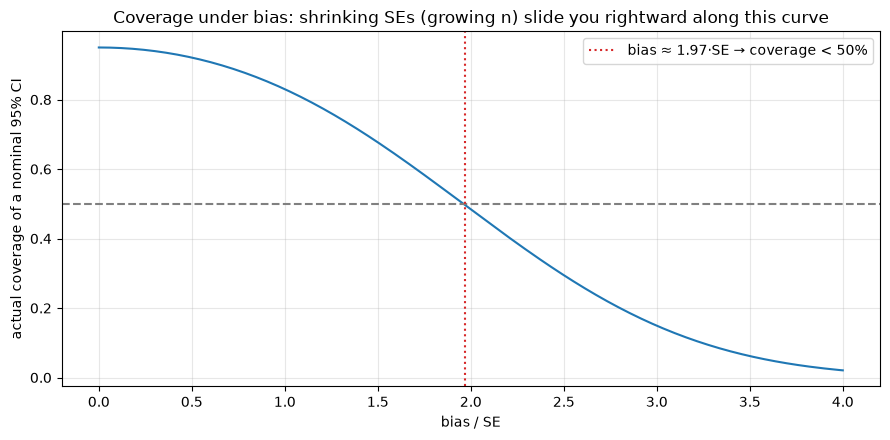

Coverage falls below 50% once bias ≈ 1.97×SE. As n grows, SE→0, so ANY fixed bias eventually lands here — the big-data paradox in one curve.


In [16]:
# --- Solution ---
b_over_se = np.linspace(0, 4, 200)
coverage_curve = stats.norm.cdf(1.96 - b_over_se) - stats.norm.cdf(-1.96 - b_over_se)
fig, ax = plt.subplots()
ax.plot(b_over_se, coverage_curve)
ax.axhline(0.5, color="gray", ls="--")
crit = b_over_se[np.argmax(coverage_curve < 0.5)]
ax.axvline(crit, color="tab:red", ls=":", label=f"bias ≈ {crit:.2f}·SE → coverage < 50%")
ax.set_xlabel("bias / SE"); ax.set_ylabel("actual coverage of a nominal 95% CI")
ax.set_title("Coverage under bias: shrinking SEs (growing n) slide you rightward along this curve")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Coverage falls below 50% once bias ≈ {crit:.2f}×SE. As n grows, SE→0, so ANY fixed bias "
      "eventually lands here — the big-data paradox in one curve.")